# 05 - Interest Vector Pipeline: TF-IDF + Dimension Reduction

This notebook implements the **interest vector construction** pipeline that transforms
raw YouTube video titles into per-channel interest profiles.

### Methodology

1. **TF-IDF Vectorisation** -- Build a corpus from all video titles, grouped by
   modularity class (community). Fit a TF-IDF model with up to 3,000 features,
   bigrams, and standard preprocessing.

2. **Interest Vector Generation** -- For each channel, compute cosine similarity
   between the channel's TF-IDF vector and each community's aggregate vector.
   This produces a vector of dimension $|\text{communities}|$ (typically ~703),
   where each component represents the channel's affinity to a community.

3. **Dimension Reduction (703 -> 30)** -- Map the original modularity classes to
   30 consolidated classes using a pre-defined mapping. The resulting 30-dimensional
   vectors are compact enough for network simulation inputs while retaining meaningful
   interest structure.

All vectors are L2-normalised so that cosine similarity between channels can be
computed as a simple dot product.

In [1]:
import sys
sys.path.insert(0, '..')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.analysis.interest_vectors import (
    build_tfidf_model,
    generate_interest_vectors,
    transform_to_30d,
    clean_text,
)
from src.utils.config import get_data_path

## Configuration

| Parameter | Description | Value |
|-----------|-------------|-------|
| `nodes_path` | YouTube channel node list with modularity classes | `data/raw/YoutubeNodes.csv` |
| `video_data_path` | Directory of per-channel video CSVs | `data/raw/video_data/` |
| `max_features` | Maximum TF-IDF vocabulary size | 3000 |
| `mapping_path` | Community mapping file (703 -> 30) | `data/raw/community_mapping.csv` |

Ensure the video data has been collected (see notebook 04) before running this pipeline.

In [2]:
# File paths
NODES_PATH = str(get_data_path('raw') / 'YoutubeNodes.csv')
VIDEO_DATA_PATH = str(get_data_path('raw') / 'video_data')
MAPPING_PATH = str(get_data_path('raw') / 'community_mapping.csv')
MAX_FEATURES = 3000

print(f"Nodes path:      {NODES_PATH}")
print(f"Video data path: {VIDEO_DATA_PATH}")
print(f"Mapping path:    {MAPPING_PATH}")
print(f"Max features:    {MAX_FEATURES}")

# Verify data availability
for path, label in [(NODES_PATH, 'Nodes CSV'), (VIDEO_DATA_PATH, 'Video data dir')]:
    exists = os.path.exists(path)
    print(f"  {label}: {'Found' if exists else 'NOT FOUND'}")

Nodes path:      /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/raw/YoutubeNodes.csv
Video data path: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/raw/video_data
Mapping path:    /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/raw/community_mapping.csv
Max features:    3000
  Nodes CSV: Found
  Video data dir: Found


## Step 1: Build the TF-IDF Model

The TF-IDF model is fitted on the combined corpus of all video titles across all
channels. Each community's aggregate text is also transformed to create reference
vectors (`class_vectors`).

The vectoriser uses:
- Unigrams and bigrams (`ngram_range=(1, 2)`).
- Minimum document frequency of 1.
- Maximum document frequency of 95% (to exclude ubiquitous terms).
- Up to 3,000 features.

In [3]:
tfidf, class_vectors, class_to_index, modularity_classes = build_tfidf_model(
    nodes_path=NODES_PATH,
    video_data_path=VIDEO_DATA_PATH,
    max_features=MAX_FEATURES,
)

print(f"TF-IDF vocabulary size:     {len(tfidf.vocabulary_)}")
print(f"Number of modularity classes: {len(modularity_classes)}")
print(f"Classes with vectors:        {len(class_vectors)}")

TF-IDF vocabulary size:     3000
Number of modularity classes: 703
Classes with vectors:        648


In [4]:
# Inspect top terms in the TF-IDF vocabulary
feature_names = tfidf.get_feature_names_out()
print(f"Sample vocabulary terms: {list(feature_names[:20])}")
print(f"Total features: {len(feature_names)}")

Sample vocabulary terms: ['aa', 'aaj', 'aarti', 'abandoned', 'about', 'abs', 'academy', 'account', 'acoustic', 'acrylic', 'acrylic painting', 'action', 'action movie', 'actually', 'ad', 'ada', 'adam', 'adventure', 'adventures', 'advice']
Total features: 3000


## Step 2: Generate Per-Channel Interest Vectors

For each channel, we:
1. Concatenate all video titles into a single document.
2. Transform it using the fitted TF-IDF model.
3. Compute cosine similarity with each community's reference vector.
4. L2-normalise the resulting similarity vector.

The output is a DataFrame with columns `[channel_name, interest_vector]` where
`interest_vector` is a comma-separated string of floats.

In [5]:
vectors_df = generate_interest_vectors(
    tfidf=tfidf,
    class_vectors=class_vectors,
    class_to_index=class_to_index,
    modularity_classes=modularity_classes,
    video_data_path=VIDEO_DATA_PATH,
    nodes_path=NODES_PATH,
)

print(f"Generated interest vectors for {len(vectors_df)} channels.")
print(f"Vector dimensionality: {len(vectors_df.iloc[0]['interest_vector'].split(','))}")
vectors_df.head()

Generated interest vectors for 5196 channels.
Vector dimensionality: 703


,channel_name,interest_vector
0,Juan_Gabriel,"0.0844826086,0.0171078877,0.0026844455,0.02399..."
1,Rclbeauty101,"0.1102380933,0.0162062939,0.0084265699,0.03179..."
2,Joana_Ceddia,"0.0958745045,0.0163925280,0.0024244931,0.03761..."
3,FARRUKOVEVO,"0.0674627091,0.0109910214,0.0062828208,0.03077..."
4,Kyoot,"0.0066114819,0.0000000000,0.0000000000,0.00000..."


### Visualise Interest Vector Distribution

We examine the distribution of interest concentration across channels. A high
maximum component indicates a channel is strongly aligned with one community;
a more uniform distribution indicates diverse interests.

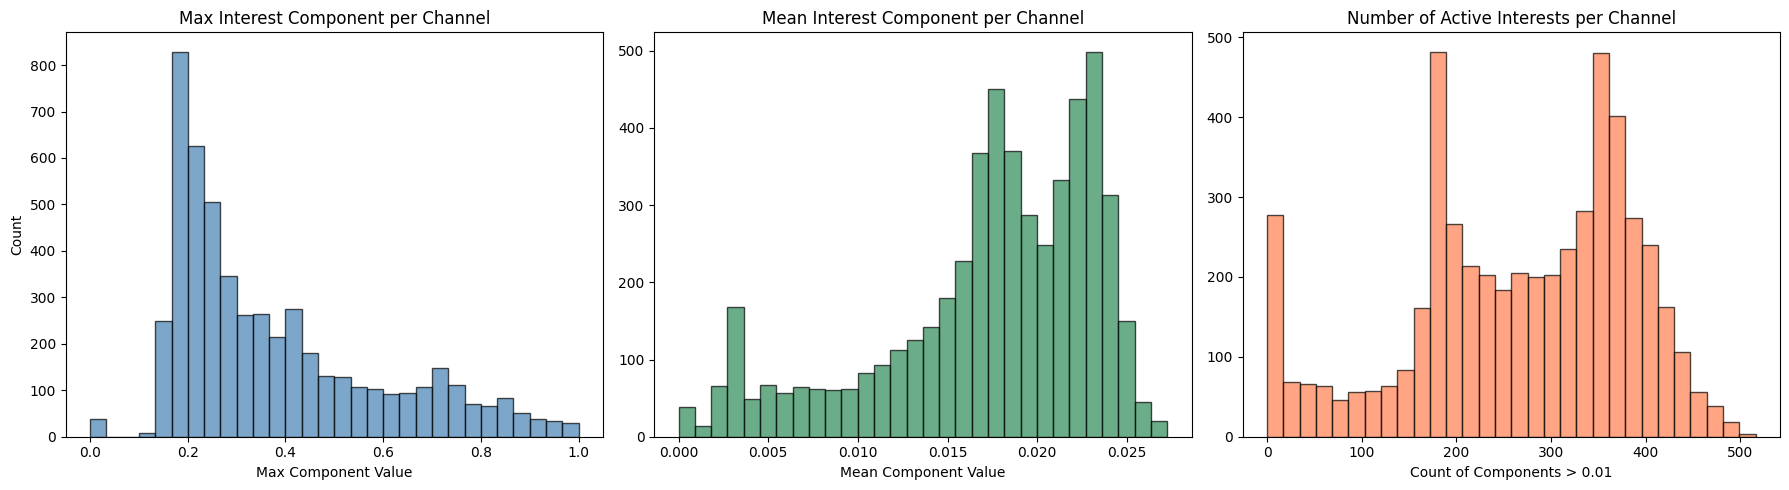

In [6]:
# Parse vectors and compute summary statistics
parsed_vectors = np.array([
    [float(x) for x in row.split(',')]
    for row in vectors_df['interest_vector']
])

max_components = np.max(parsed_vectors, axis=1)
mean_components = np.mean(parsed_vectors, axis=1)
nonzero_counts = np.sum(parsed_vectors > 0.01, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(max_components, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title('Max Interest Component per Channel')
axes[0].set_xlabel('Max Component Value')
axes[0].set_ylabel('Count')

axes[1].hist(mean_components, bins=30, edgecolor='black', alpha=0.7, color='seagreen')
axes[1].set_title('Mean Interest Component per Channel')
axes[1].set_xlabel('Mean Component Value')

axes[2].hist(nonzero_counts, bins=30, edgecolor='black', alpha=0.7, color='coral')
axes[2].set_title('Number of Active Interests per Channel')
axes[2].set_xlabel('Count of Components > 0.01')

plt.tight_layout()
plt.show()

## Step 3: Reduce to 30 Dimensions

The original interest vectors have one dimension per modularity class (typically ~703).
We use a pre-defined community mapping to consolidate these into 30 broader interest
categories. Components belonging to the same consolidated class are summed, and the
result is re-normalised.

In [7]:
if os.path.exists(MAPPING_PATH):
    mapping_df = pd.read_csv(MAPPING_PATH)
    print(f"Mapping loaded: {len(mapping_df)} entries")
    print(f"Original classes: {mapping_df['original_class'].nunique()}")
    print(f"New classes:      {mapping_df['new_class'].nunique()}")

    vectors_30d = transform_to_30d(vectors_df, mapping_df)
    print(f"\nReduced vectors: {len(vectors_30d)} channels")
    print(f"New dimensionality: {len(vectors_30d.iloc[0]['interest_vector'].split(','))}")
    vectors_30d.head()
else:
    print(f"Mapping file not found: {MAPPING_PATH}")
    print("Skipping dimension reduction step.")

Mapping file not found: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/raw/community_mapping.csv
Skipping dimension reduction step.


## Save Results

The generated interest vectors are saved to CSV for use in downstream analysis
(network construction, statistical analysis, simulation comparison).

In [8]:
# Save full-dimensional vectors
output_full = str(get_data_path('processed') / 'interest_vectors_full.csv')
os.makedirs(os.path.dirname(output_full), exist_ok=True)
vectors_df.to_csv(output_full, index=False)
print(f"Full vectors saved to: {output_full}")

# Save 30-dimensional vectors (if mapping was available)
if os.path.exists(MAPPING_PATH):
    output_30d = str(get_data_path('processed') / 'interest_vectors_30d.csv')
    vectors_30d.to_csv(output_30d, index=False)
    print(f"30D vectors saved to:  {output_30d}")

Full vectors saved to: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/processed/interest_vectors_full.csv
